# **GITHUB LOGGING & CODE PUSH SCRIPT**

In [2]:
from google.colab import userdata
import sys, os

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw1"


os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")
sys.path.append(f"/content/{REPO}/common")
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw1:=== Session started for hw1 ===


Working directory: /content/data266-5937/hw1
[main 286d5cb] hw1: session start
 2 files changed, 1 insertion(+)
 create mode 100644 common/__pycache__/colab_bootstrap.cpython-313.pyc
 create mode 100644 hw1/RUN_LOG.txt
 


In [1]:
SID4  = 5937
SEED  = SID4
SLICE = SID4 % 1000 #937
HP_ID = SID4 % 6 #3

CLS_A = SID4 % 10 #7
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10 #6

In [ ]:
import random
import numpy as np
import torch

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
print(HW_PATH)
print(REPO_PATH)
logger.info("Sanity check: logger is working")
git_commit_push(REPO_PATH, "hw1: sanity check commit")

INFO:/content/data266-5937/hw1:Sanity check: logger is working


/content/data266-5937/hw1
/content/data266-5937
[main 9ac8140] hw1: sanity check commit
 1 file changed, 1 insertion(+)
 


In [4]:
import pandas as pd

# **PREPROCESSING & FEATURE ENGINEERING**

In [64]:
df = pd.read_csv("/content/diabetes.csv", header=None, names=column_names)
display(df.head())
display(df.info())
display(df.describe())

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Outcome
0,-0.294118,0.487437,0.180328,-0.292929,0.000000,0.001490,-0.531170,-0.033333,0
1,-0.882353,-0.145729,0.081967,-0.414141,0.000000,-0.207153,-0.766866,-0.666667,1
2,-0.058824,0.839196,0.049180,0.000000,0.000000,-0.305514,-0.492741,-0.633333,0
3,-0.882353,-0.105528,0.081967,-0.535354,-0.777778,-0.162444,-0.923997,0.000000,1
4,0.000000,0.376884,-0.344262,-0.292929,-0.602837,0.284650,0.887276,-0.600000,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 759 entries, 0 to 758
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature_1  759 non-null    float64
 1   Feature_2  759 non-null    float64
 2   Feature_3  759 non-null    float64
 3   Feature_4  759 non-null    float64
 4   Feature_5  759 non-null    float64
 5   Feature_6  759 non-null    float64
 6   Feature_7  759 non-null    float64
 7   Feature_8  759 non-null    float64
 8   Outcome    759 non-null    int64  
dtypes: float64(8), int64(1)
memory usage: 53.5 KB


None

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Outcome
count,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000
mean,-0.407657,0.218563,0.176505,-0.289735,-0.323534,-0.032245,-0.663253,-0.516162,0.653491
std,0.386260,0.306419,0.201287,0.258480,0.375544,0.205376,0.283056,0.400794,0.476171
min,-0.882353,-0.557789,-0.606557,-0.858586,-0.966903,-0.457526,-0.994876,-0.966667,0.000000
25%,-0.764706,-0.005025,0.016393,-0.494949,-0.716312,-0.178837,-0.858241,-0.866667,0.000000
50%,-0.529412,0.165829,0.180328,-0.292929,0.000000,-0.034277,-0.747225,-0.633333,1.000000
75%,0.000000,0.407035,0.311475,0.000000,0.000000,0.087929,-0.531597,-0.233333,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 758 entries, 0 to 757
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   -0.294118   758 non-null    float64
 1   0.487437    758 non-null    float64
 2   0.180328    758 non-null    float64
 3   -0.292929   758 non-null    float64
 4   0           758 non-null    float64
 5   0.00149028  758 non-null    float64
 6   -0.53117    758 non-null    float64
 7   -0.0333333  758 non-null    float64
 8   0.1         758 non-null    int64  
dtypes: float64(8), int64(1)
memory usage: 53.4 KB


None

,-0.294118,0.487437,0.180328,-0.292929,0,0.00149028,-0.53117,-0.0333333,0.1
count,758.000000,758.000000,758.000000,758.000000,758.000000,758.000000,758.000000,758.000000,758.000000
mean,-0.407807,0.218208,0.176500,-0.289731,-0.323961,-0.032289,-0.663427,-0.516799,0.654354
std,0.386493,0.306465,0.201420,0.258651,0.375608,0.205508,0.283202,0.400674,0.475893
min,-0.882353,-0.557789,-0.606557,-0.858586,-0.966903,-0.457526,-0.994876,-0.966667,0.000000
25%,-0.764706,-0.005025,0.016393,-0.494949,-0.716312,-0.179583,-0.858241,-0.866667,0.000000
50%,-0.529412,0.165829,0.180328,-0.292929,0.000000,-0.034277,-0.748506,-0.633333,1.000000
75%,0.000000,0.407035,0.311475,0.000000,0.000000,0.087929,-0.532451,-0.233333,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [14]:
df.columns

Index(['-0.294118', '0.487437', '0.180328', '-0.292929', '0', '0.00149028',
       '-0.53117', '-0.0333333', '0.1'],
      dtype='object')

In [11]:
column_names = [f"Feature_{i}" for i in range(1, 9)] + ["Outcome"]

In [9]:
display(df.shape)

(758, 9)

In [10]:
df.isnull().sum()

,0
-0.294118,0
0.487437,0
0.180328,0
-0.292929,0
0,0
0.00149028,0
-0.53117,0
-0.0333333,0
0.1,0


In [20]:
df = pd.read_csv("/content/diabetes.csv", header=None, names=column_names)

In [21]:
display(df.head())

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Outcome
0,-0.294118,0.487437,0.180328,-0.292929,0.000000,0.001490,-0.531170,-0.033333,0
1,-0.882353,-0.145729,0.081967,-0.414141,0.000000,-0.207153,-0.766866,-0.666667,1
2,-0.058824,0.839196,0.049180,0.000000,0.000000,-0.305514,-0.492741,-0.633333,0
3,-0.882353,-0.105528,0.081967,-0.535354,-0.777778,-0.162444,-0.923997,0.000000,1
4,0.000000,0.376884,-0.344262,-0.292929,-0.602837,0.284650,0.887276,-0.600000,0


In [26]:
df.duplicated().sum()

np.int64(0)

In [31]:
print(df['Outcome'].value_counts())

Outcome
1    496
0    263
Name: count, dtype: int64


In [39]:
variance = df[column_names].var()
print(variance)

Feature_1    0.149197
Feature_2    0.093892
Feature_3    0.040517
Feature_4    0.066812
Feature_5    0.141033
Feature_6    0.042179
Feature_7    0.080121
Feature_8    0.160636
Outcome      0.226739
dtype: float64


In [42]:
low_variance_cols = variance[variance < 0.01].index.tolist()
display(low_variance_cols)
df = df.drop(columns=low_variance_cols)
feature_cols = [col for col in df.columns if col != 'target']
print(feature_cols)

[]

['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Feature_6', 'Feature_7', 'Feature_8', 'Outcome']


# **VISUALIZATIONS**

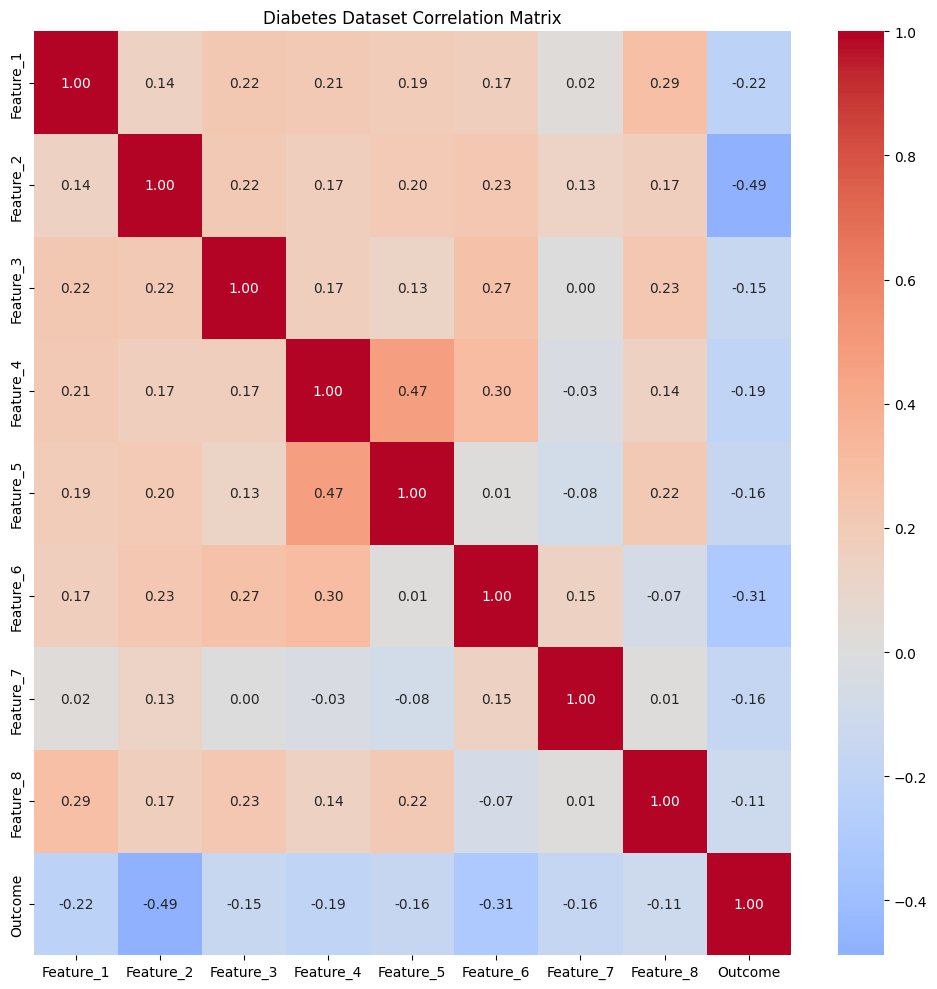

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Diabetes Dataset Correlation Matrix")
plt.tight_layout()
plt.savefig(f"{HW_PATH}/Diabetes Dataset Correlation Matrix1.png")
plt.show()

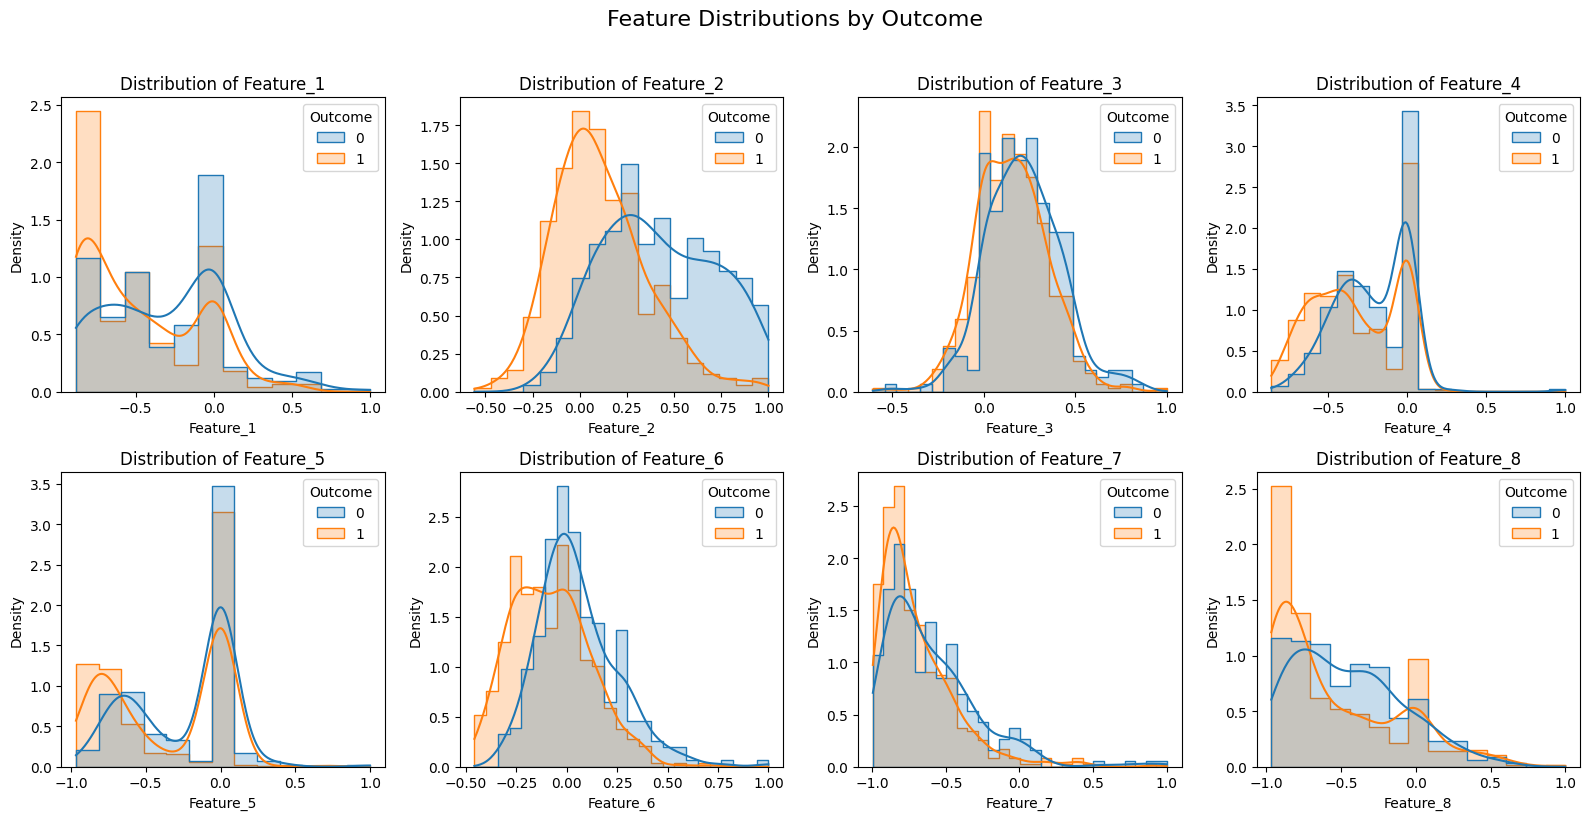

In [46]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for feature, axis in zip(column_names[:-1], axes.ravel()):
    sns.histplot(data=df, x=feature, hue="Outcome", kde=True,
                 element="step", stat="density", common_norm=False, ax=axis)
    axis.set_title(f"Distribution of {feature}")
fig.suptitle("Feature Distributions by Outcome", fontsize=16, y=1.02)
fig.tight_layout()
plt.savefig(f"{HW_PATH}/Feature Distributions by Outcome.png")
plt.show()

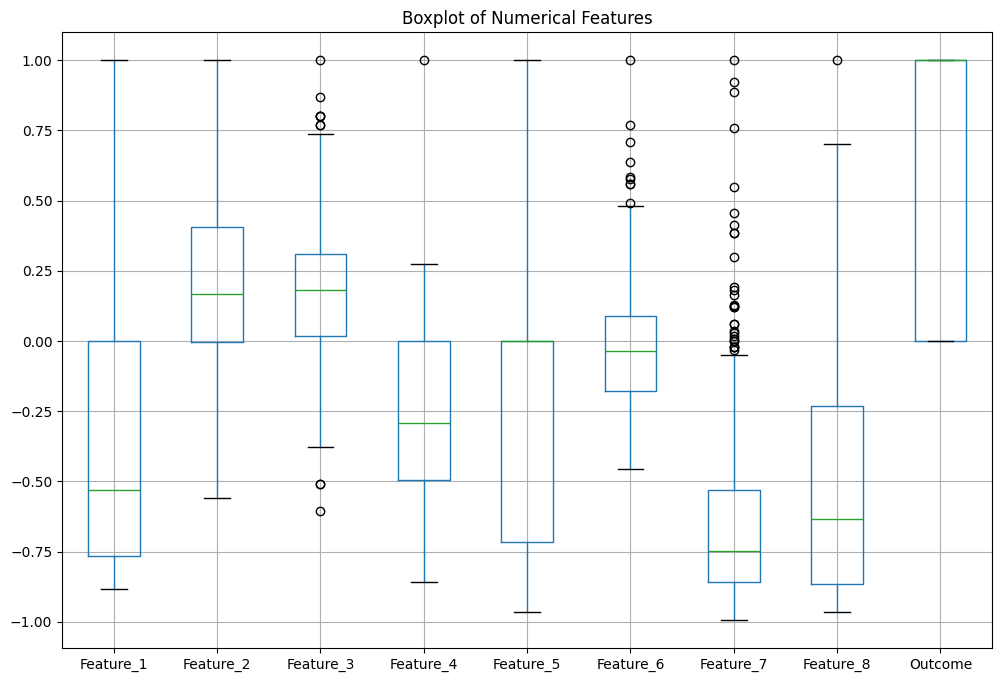

In [48]:
plt.figure(figsize=(12, 8))
df[column_names].boxplot()
plt.title("Boxplot of Numerical Features")
plt.savefig(f"{HW_PATH}/Boxplot of Numerical Features.png")
plt.show()

/tmp/ipykernel_4050/2076888365.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Outcome', palette='pastel')


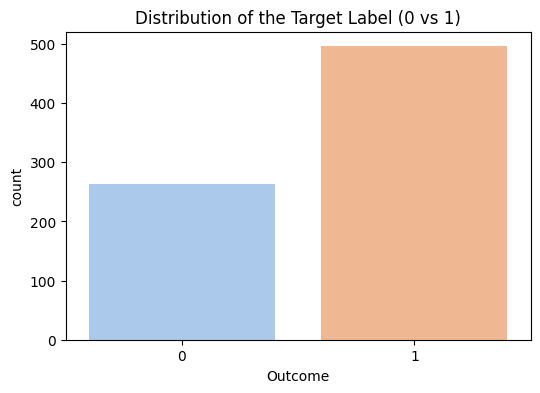

In [49]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Outcome', palette='pastel')
plt.title("Distribution of the Target Label (0 vs 1)")
plt.savefig(f"{HW_PATH}/Distribution of the Target Label (0 vs 1).png")
plt.show()

In [50]:
logger.info("Uploading visualization images")
git_commit_push(REPO_PATH, "hw1: visualizations")

INFO:/content/data266-5937/hw1:Uploading visualization images


[main 1fcc773] hw1: visualizations
 5 files changed, 1 insertion(+)
 rewrite hw1/Boxplot of Numerical Features.png (99%)
 create mode 100644 hw1/Diabetes Dataset Correlation Matrix1.png
 rewrite hw1/Distribution of the Target Label (0 vs 1).png (99%)
 rewrite hw1/Feature Distributions by Outcome.png (99%)
 


# **DATASET SPLITTING**

In [61]:
import torch
import torch.nn as nn
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [66]:
import numpy as np
X = df.drop(columns="Outcome").to_numpy(dtype=np.float32)
y = df["Outcome"].to_numpy(dtype=np.float32)
all_indices = np.arange(len(df))
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

logger.info(f"Split fixed: train={len(X_train)}, val={len(X_val)}, test={len(X_test)}, random_state={SEED}")

INFO:/content/data266-5937/hw1:Split fixed: train=531, val=114, test=114, random_state=5937


In [71]:
class FFN(nn.Module):
    def __init__(self, input_dim, hidden_layers):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_layers:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_pytorch(hidden_layers, lr, epochs, seed, X_train, y_train, X_val, y_val, X_test, y_test):
    torch.manual_seed(seed)
    np.random.seed(seed)

    Xtr = torch.tensor(X_train, dtype=torch.float32)
    ytr = torch.tensor(y_train, dtype=torch.float32).view(-1,1)
    Xva = torch.tensor(X_val, dtype=torch.float32)
    yva = torch.tensor(y_val, dtype=torch.float32).view(-1,1)
    Xte = torch.tensor(X_test, dtype=torch.float32)
    yte = torch.tensor(y_test, dtype=torch.float32).view(-1,1)

    model = FFN(X_train.shape[1], hidden_layers)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCELoss()

    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(Xtr)
        loss = criterion(out, ytr)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_out = model(Xva)
            val_loss = criterion(val_out, yva)

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

    with torch.no_grad():
        test_pred = (model(Xte) > 0.5).float()
        test_acc = (test_pred.eq(yte).sum() / len(yte)).item()

    return test_acc, train_losses, val_losses

In [68]:
def train_tensorflow(hidden_layers, lr, epochs, seed, X_train, y_train, X_val, y_val, X_test, y_test):
    tf.random.set_seed(seed)
    np.random.seed(seed)

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(X_train.shape[1],)))
    for h in hidden_layers:
        model.add(tf.keras.layers.Dense(h, activation="relu"))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=["accuracy"])

    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                         epochs=epochs, verbose=0)

    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    return test_acc, history.history["loss"], history.history["val_loss"]

In [69]:
BASELINE_CONFIG = {"hidden_layers": [64, 32], "lr": 0.001, "epochs": 30}
MODIFIED_CONFIG = {"hidden_layers": [64, 32], "lr": 0.0003, "epochs": 30}   # HP_ID=3

logger.info(f"HP_ID={HP_ID} -> Modified config: {MODIFIED_CONFIG}")

INFO:/content/data266-5937/hw1:HP_ID=3 -> Modified config: {'hidden_layers': [64, 32], 'lr': 0.0003, 'epochs': 30}


In [72]:
seeds = [SEED, SEED+1, SEED+2]
pt_baseline_accs, pt_modified_accs = [], []
pt_baseline_curves, pt_modified_curves = None, None

for s in seeds:
    acc, tr_loss, val_loss = train_pytorch(**BASELINE_CONFIG, seed=s,
                                            X_train=X_train, y_train=y_train,
                                            X_val=X_val, y_val=y_val,
                                            X_test=X_test, y_test=y_test)
    pt_baseline_accs.append(acc)
    logger.info(f"[PyTorch baseline] seed={s} test_acc={acc:.4f}")
    if s == SEED:
        pt_baseline_curves = (tr_loss, val_loss)

for s in seeds:
    acc, tr_loss, val_loss = train_pytorch(**MODIFIED_CONFIG, seed=s,
                                            X_train=X_train, y_train=y_train,
                                            X_val=X_val, y_val=y_val,
                                            X_test=X_test, y_test=y_test)
    pt_modified_accs.append(acc)
    logger.info(f"[PyTorch modified HP_ID={HP_ID}] seed={s} test_acc={acc:.4f}")
    if s == SEED:
        pt_modified_curves = (tr_loss, val_loss)

pt_baseline_mean, pt_baseline_std = np.mean(pt_baseline_accs), np.std(pt_baseline_accs)
pt_modified_mean, pt_modified_std = np.mean(pt_modified_accs), np.std(pt_modified_accs)


INFO:/content/data266-5937/hw1:[PyTorch baseline] seed=5937 test_acc=0.7719
INFO:/content/data266-5937/hw1:[PyTorch baseline] seed=5938 test_acc=0.7632
INFO:/content/data266-5937/hw1:[PyTorch baseline] seed=5939 test_acc=0.6930
INFO:/content/data266-5937/hw1:[PyTorch modified HP_ID=3] seed=5937 test_acc=0.6491
INFO:/content/data266-5937/hw1:[PyTorch modified HP_ID=3] seed=5938 test_acc=0.6404
INFO:/content/data266-5937/hw1:[PyTorch modified HP_ID=3] seed=5939 test_acc=0.6754


In [73]:
logger.info(f"[PyTorch] baseline mean={pt_baseline_mean:.4f} std={pt_baseline_std:.4f}")
logger.info(f"[PyTorch] modified mean={pt_modified_mean:.4f} std={pt_modified_std:.4f}")

git_commit_push(REPO_PATH, "hw1: PyTorch baseline + HP_ID modified, 3-seed runs complete")

INFO:/content/data266-5937/hw1:[PyTorch] baseline mean=0.7427 std=0.0353
INFO:/content/data266-5937/hw1:[PyTorch] modified mean=0.6550 std=0.0149


[main 9bac2dd] hw1: PyTorch baseline + HP_ID modified, 3-seed runs complete
 1 file changed, 10 insertions(+)
 


In [74]:
tf_baseline_accs, tf_modified_accs = [], []
tf_baseline_curves, tf_modified_curves = None, None

for s in seeds:
    acc, tr_loss, val_loss = train_tensorflow(**BASELINE_CONFIG, seed=s,
                                               X_train=X_train, y_train=y_train,
                                               X_val=X_val, y_val=y_val,
                                               X_test=X_test, y_test=y_test)
    tf_baseline_accs.append(acc)
    logger.info(f"[TensorFlow baseline] seed={s} test_acc={acc:.4f}")
    if s == SEED:
        tf_baseline_curves = (tr_loss, val_loss)

for s in seeds:
    acc, tr_loss, val_loss = train_tensorflow(**MODIFIED_CONFIG, seed=s,
                                               X_train=X_train, y_train=y_train,
                                               X_val=X_val, y_val=y_val,
                                               X_test=X_test, y_test=y_test)
    tf_modified_accs.append(acc)
    logger.info(f"[TensorFlow modified HP_ID={HP_ID}] seed={s} test_acc={acc:.4f}")
    if s == SEED:
        tf_modified_curves = (tr_loss, val_loss)

tf_baseline_mean, tf_baseline_std = np.mean(tf_baseline_accs), np.std(tf_baseline_accs)
tf_modified_mean, tf_modified_std = np.mean(tf_modified_accs), np.std(tf_modified_accs)

INFO:/content/data266-5937/hw1:[TensorFlow baseline] seed=5937 test_acc=0.7895
INFO:/content/data266-5937/hw1:[TensorFlow baseline] seed=5938 test_acc=0.7982
INFO:/content/data266-5937/hw1:[TensorFlow baseline] seed=5939 test_acc=0.7982
INFO:/content/data266-5937/hw1:[TensorFlow modified HP_ID=3] seed=5937 test_acc=0.7895
INFO:/content/data266-5937/hw1:[TensorFlow modified HP_ID=3] seed=5938 test_acc=0.7895
INFO:/content/data266-5937/hw1:[TensorFlow modified HP_ID=3] seed=5939 test_acc=0.7368


In [76]:
logger.info(f"[TensorFlow] baseline mean={tf_baseline_mean:.4f} std={tf_baseline_std:.4f}")
logger.info(f"[TensorFlow] modified mean={tf_modified_mean:.4f} std={tf_modified_std:.4f}")

git_commit_push(REPO_PATH, "hw1: TensorFlow baseline + HP_ID modified, 3-seed runs complete")

INFO:/content/data266-5937/hw1:[TensorFlow] baseline mean=0.7953 std=0.0041
INFO:/content/data266-5937/hw1:[TensorFlow] modified mean=0.7719 std=0.0248


[main 512851d] hw1: TensorFlow baseline + HP_ID modified, 3-seed runs complete
 1 file changed, 8 insertions(+)
 


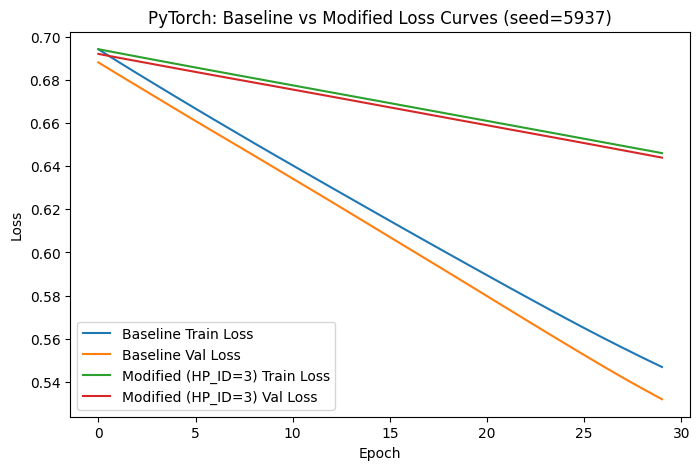

In [77]:
plt.figure(figsize=(8,5))
plt.plot(pt_baseline_curves[0], label="Baseline Train Loss")
plt.plot(pt_baseline_curves[1], label="Baseline Val Loss")
plt.plot(pt_modified_curves[0], label=f"Modified (HP_ID={HP_ID}) Train Loss")
plt.plot(pt_modified_curves[1], label=f"Modified (HP_ID={HP_ID}) Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"PyTorch: Baseline vs Modified Loss Curves (seed={SEED})")
plt.legend()
plt.savefig(f"{HW_PATH}/pytorch_loss_curves.png", bbox_inches="tight", dpi=150)
plt.show()

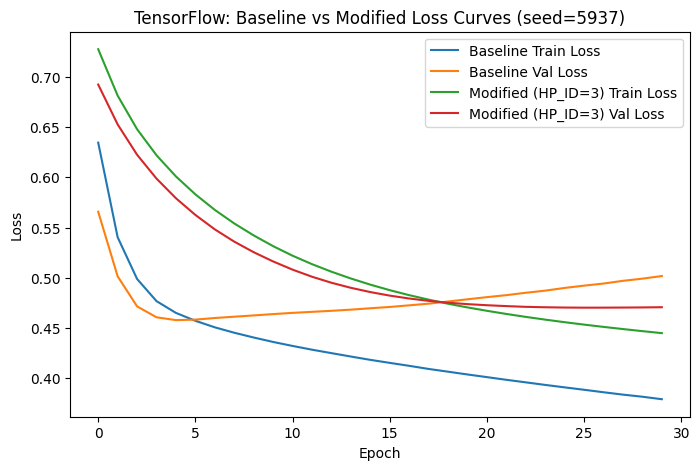

In [78]:
plt.figure(figsize=(8,5))
plt.plot(tf_baseline_curves[0], label="Baseline Train Loss")
plt.plot(tf_baseline_curves[1], label="Baseline Val Loss")
plt.plot(tf_modified_curves[0], label=f"Modified (HP_ID={HP_ID}) Train Loss")
plt.plot(tf_modified_curves[1], label=f"Modified (HP_ID={HP_ID}) Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"TensorFlow: Baseline vs Modified Loss Curves (seed={SEED})")
plt.legend()
plt.savefig(f"{HW_PATH}/tensorflow_loss_curves.png", bbox_inches="tight", dpi=150)
plt.show()

In [79]:
summary = f"""
## HW1 Results — HP_ID={HP_ID} (Modified config: {MODIFIED_CONFIG})

| Framework  | Model    | Mean Test Acc | Std Test Acc |
|------------|----------|----------------|----------------|
| PyTorch    | Baseline | {pt_baseline_mean:.4f} | {pt_baseline_std:.4f} |
| PyTorch    | Modified | {pt_modified_mean:.4f} | {pt_modified_std:.4f} |
| TensorFlow | Baseline | {tf_baseline_mean:.4f} | {tf_baseline_std:.4f} |
| TensorFlow | Modified | {tf_modified_mean:.4f} | {tf_modified_std:.4f} |
"""
print(summary)


## HW1 Results — HP_ID=3 (Modified config: {'hidden_layers': [64, 32], 'lr': 0.0003, 'epochs': 30})

| Framework  | Model    | Mean Test Acc | Std Test Acc |
|------------|----------|----------------|----------------|
| PyTorch    | Baseline | 0.7427 | 0.0353 |
| PyTorch    | Modified | 0.6550 | 0.0149 |
| TensorFlow | Baseline | 0.7953 | 0.0041 |
| TensorFlow | Modified | 0.7719 | 0.0248 |



In [80]:
git_commit_push(REPO_PATH, "hw1: PyTorch baseline + HP_ID modified, 3-seed runs complete")

[main 94e5597] hw1: PyTorch baseline + HP_ID modified, 3-seed runs complete
 2 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 hw1/pytorch_loss_curves.png
 create mode 100644 hw1/tensorflow_loss_curves.png
 


In [81]:
git_commit_push(REPO_PATH, "hw1: TensorFlow baseline + HP_ID modified, 3-seed runs complete")

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
 


In [82]:
git_commit_push(REPO_PATH, "hw1: loss curve figures for both frameworks")

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
 


In [83]:
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(summary)

git_commit_push(REPO_PATH, "hw1: METRICS.md updated with accuracy table")

[main ff62d68] hw1: METRICS.md updated with accuracy table
 1 file changed, 9 insertions(+)
 create mode 100644 hw1/METRICS.md
 


## **CONCLUSION**


HP_ID = 3 -> Modified config: hidden layers [64, 32], learning rate 0.0003, 30 epochs (baseline: same architecture, learning rate 0.001)


---

**Results (mean ± std test accuracy, 3 seeds: SEED, SEED+1, SEED+2):**

| Framework  | Model    | Mean Test Acc | Std Test Acc |
|------------|----------|----------------|----------------|
| PyTorch    | Baseline | 0.7427         | 0.0353         |
| PyTorch    | Modified | 0.6550         | 0.0149         |
| TensorFlow | Baseline | 0.7953         | 0.0041         |
| TensorFlow | Modified | 0.7719         | 0.0248         |



---
**PYTORCH**: Both baseline and modified curves are decreasing at epoch 30 without flattening, meaning neither model has converged in 30 epochs. The modified model has a lower test accuracy than the baseline, which points to underfitting driven by smaller learning rate and lesser number of epochs. This is also validated by the modified model's loss which drops far more slowly (from 0.695 to 0.645 over 30 epochs) than the baseline's (0.695 to 0.55).

---
**TensorFlow:** The baseline's validation loss dips and then rises back up by epoch 30 even when the training loss is falling. This shows overfitting where both are diverging. The modified model's train and validation curves are adjacent and converging while reaching epoch 30. This shows no overfitting and grpahs smoothly moving towards convergence. Although, modified model is performing better, it has lesser test accuracy suggests some underfitting.

---
**Overall:** Across both frameworks, HP_ID=3's lower learning rate (0.0003 vs 0.001)
underperforms the baseline in accuracy. In PyTorch, the modified model is clearly
underfit (curves still steeply decreasing, incomplete convergence). In TensorFlow,
the modified model is closer to a well-behaved fit than the baseline (no
overfitting), but likely still needs more epochs to fully close the accuracy gap.
This is consistent with the standard trade-off: lower learning rates improve
training stability and reduce overfitting risk, but need a longer schedule to reach
the same performance as a higher learning rate within a fixed epoch budget.



In [84]:
logger.info(f"Conclusion assessed and provided in the file")

INFO:/content/data266-5937/hw1:Conclusion assessed and provided in the file
